Gowtham pankaj
Accuracy: 1.0

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        26
           1       1.00      1.00      1.00        19

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



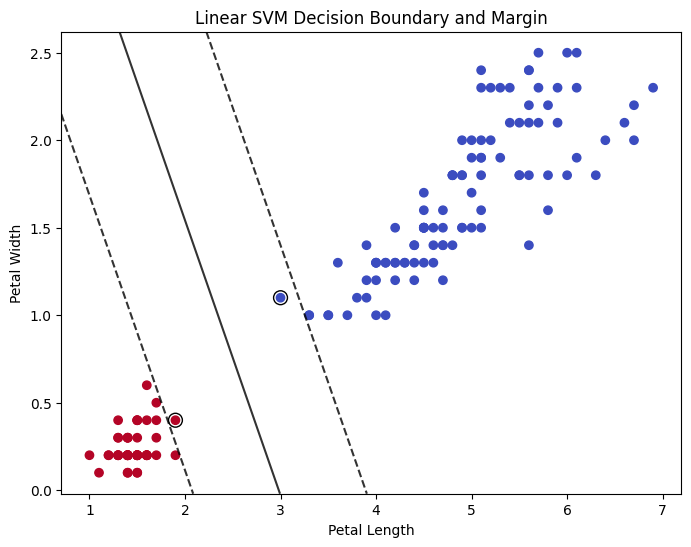

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

# Load Iris Dataset
iris = datasets.load_iris()

# Use only Petal Length and Petal Width
X = iris.data[:, [2, 3]]

# Binary Classification
# Setosa = 1
# Non-Setosa = 0
y = (iris.target == 0).astype(int)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

# Linear SVM
svm_model = SVC(
    kernel='linear',
    C=1
)

svm_model.fit(X_train, y_train)

# Prediction
y_pred = svm_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Nidhun")
print("Accuracy:", accuracy)

print("\nClassification Report")
print(classification_report(y_test, y_pred))

# Plot Decision Boundary
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap='coolwarm'
)

ax = plt.gca()

xlim = ax.get_xlim()
ylim = ax.get_ylim()

xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)

YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T

Z = svm_model.decision_function(xy)
Z = Z.reshape(XX.shape)

# Decision Boundary
ax.contour(
    XX,
    YY,
    Z,
    colors='k',
    levels=[-1, 0, 1],
    alpha=0.8,
    linestyles=['--', '-', '--']
)

# Support Vectors
ax.scatter(
    svm_model.support_vectors_[:, 0],
    svm_model.support_vectors_[:, 1],
    s=100,
    linewidth=1,
    facecolors='none',
    edgecolors='black'
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Linear SVM Decision Boundary and Margin")

plt.show()


